<a href="https://colab.research.google.com/github/claireeelah/ORES5160-2026/blob/main/week11assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Q1. Reading the CSV File (pandas + csv)

	1.	Use the csv module to open and print the first 5 rows of est2018-pop-res.csv.

	2.	Then use pandas.read_csv() to load the same file into a DataFrame.

	•	Display the shape (rows × columns).

	•	Print the list of column names.

	3.	Which column represents total population? Display the top 5 most populous states


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
df= pd.read_csv('/content/drive/MyDrive/est2018-pop-res.csv')

In [ ]:
df.head(5)

,SUMLEV,REGION,DIVISION,STATE,NAME,POPESTIMATE2018,POPEST18PLUS2018,PCNT_POPEST18PLUS
0,10,0,0,0,United States,327167434,253768092,77.6
1,40,3,6,1,Alabama,4887871,3798031,77.7
2,40,4,9,2,Alaska,737438,553622,75.1
3,40,4,8,4,Arizona,7171646,5528989,77.1
4,40,3,7,5,Arkansas,3013825,2310645,76.7


In [ ]:
df.shape

(53, 8)

In [ ]:
df.columns

Index(['SUMLEV', 'REGION', 'DIVISION', 'STATE', 'NAME', 'POPESTIMATE2018',
       'POPEST18PLUS2018', 'PCNT_POPEST18PLUS'],
      dtype='object')

In [ ]:
states = df[df["SUMLEV"]== 40]
states = states.sort_values("POPESTIMATE2018", ascending= False)
states[["NAME", "POPESTIMATE2018"]].head(5)

,NAME,POPESTIMATE2018
5,California,39557045
44,Texas,28701845
10,Florida,21299325
33,New York,19542209
39,Pennsylvania,12807060


In [ ]:
#POPESTIMATE2018 represents the total population.
import csv
with open ('/content/drive/MyDrive/est2018-pop-res.csv') as f:
  line = f.readline().strip()
  values = line.split(",")
  print (values)

['SUMLEV', 'REGION', 'DIVISION', 'STATE', 'NAME', 'POPESTIMATE2018', 'POPEST18PLUS2018', 'PCNT_POPEST18PLUS']


Q2. Basic Statistical Analysis (pandas)

	1.	Compute the average population across all states.

	2.	Find which region has the highest total population.

	3.	Plot a bar chart showing the population by region (use matplotlib)

In [ ]:
#average population
states = df[df["SUMLEV"]== 40]
states["POPESTIMATE2018"].mean()


np.float64(6353126.673076923)

In [ ]:
#Region with highest total population
states.groupby("REGION")["POPESTIMATE2018"].sum().sort_values(ascending=False)


,POPESTIMATE2018
REGION,
3,124753948
4,77993663
2,68308744
1,56111079
X,3195153


In [ ]:
#barchart population by regoion
import matplotlib.pyplot as plt


In [ ]:
import matplotlib.pyplot as plt
import importlib

plt = importlib.reload(plt)

/tmp/ipykernel_2271/4096562628.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


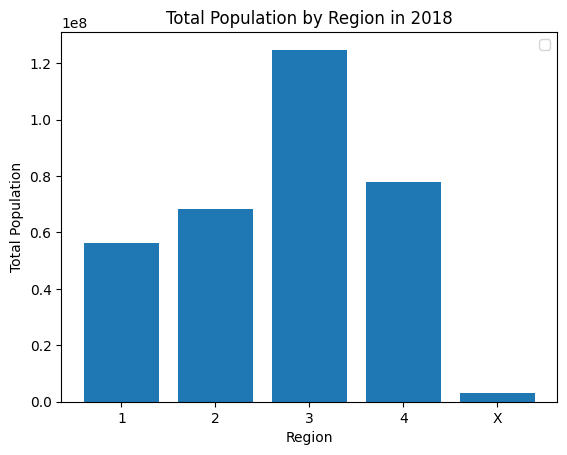

In [ ]:
region_pop = states.groupby("REGION")["POPESTIMATE2018"].sum()
plt.bar (region_pop.index, region_pop.values)
plt.xlabel('Region')
plt.ylabel('Total Population')
plt.title('Total Population by Region in 2018')
plt.legend()
plt.show()

Q3. Parsing the JSON File (FHIR structure)

Using json module:

	1.	Load patient.json into a Python dictionary.

	2.	Extract and print:

	•	Patient’s full official name

	•	Gender and birth date

	•	Current address (city, state, postal code)
  
	3.	Count how many phone numbers the patient has, and list their types (e.g., work, mobile, home).

In [ ]:
import json
from pathlib import Path
patient_file= "/content/drive/MyDrive/patient.json"

In [ ]:
systems = json.load(open(patient_file))
systems

{'resourceType': 'Patient',
 'id': 'example',
 'identifier': [{'use': 'usual',
   'type': {'coding': [{'system': 'http://terminology.hl7.org/CodeSystem/v2-0203',
      'code': 'MR'}]},
   'system': 'urn:oid:1.2.36.146.595.217.0.1',
   'value': '12345',
   'period': {'start': '2001-05-06'},
   'assigner': {'display': 'Acme Healthcare'}}],
 'active': True,
 'name': [{'use': 'official',
   'family': 'Chalmers',
   'given': ['Peter', 'James']},
  {'use': 'usual', 'given': ['Jim']},
  {'use': 'maiden',
   'family': 'Windsor',
   'given': ['Peter', 'James'],
   'period': {'end': '2002'}}],
 'telecom': [{'use': 'home'},
  {'system': 'phone', 'value': '(03) 5555 6473', 'use': 'work', 'rank': 1},
  {'system': 'phone', 'value': '(03) 3410 5613', 'use': 'mobile', 'rank': 2},
  {'system': 'phone',
   'value': '(03) 5555 8834',
   'use': 'old',
   'period': {'end': '2014'}}],
 'gender': 'male',
 'birthDate': '1974-12-25',
 '_birthDate': {'extension': [{'url': 'http://hl7.org/fhir/StructureDefinitio

In [ ]:
#official first name and last name
for name in systems.get("name"):
  if name.get("use") == "official":
    first_name = name.get("given")
    last_name = name.get("family")
    print(first_name, last_name)


['Peter', 'James'] Chalmers


In [ ]:
#gender
gender = systems.get("gender")
print(gender)

male


In [ ]:
#birth date
birthdate= systems.get("birthDate")
print(birthdate)

1974-12-25


In [ ]:
#current address (city, state, postal code)
for address in systems.get("address"):
  city = address.get("city")
  state = address.get ("state")
  postal_code = address.get("postalCode")
  print(city, state, postal_code)

PleasantVille Vic 3999


In [ ]:
#phone numbers and types
for phone in systems.get("telecom"):
  phone_type = phone.get("use")
  phone_number = phone.get("value")
  print(phone_type, phone_number)


home None
work (03) 5555 6473
mobile (03) 3410 5613
old (03) 5555 8834
